In [1]:
import os
import numpy as np
import cv2 as cv
from skimage.io import imread
import matplotlib.pyplot as plt

# libraries to test
import sys
sys.path.append("../")
from frangi_2dfilter import frangi_2Dfilter
from fuzzy_thresholding import fuzzy_thresholding
from adaptive_thresholding import adaptive_thresholding

# Testing
We will be testing the Frangi 2D and Adaptive thresholding translations to ensure they work properly for skeletonization

# Utilities

In [2]:
def BinarizeImage(Im:np.ndarray, frangi_sigma = 8, frangi_enabled = True, method = "Fuzzy Means") -> np.ndarray:
    """
    Binarizes an image using the selected method and options from the GUI app.

    Parameters:
    - app: GUI application object containing UI state (e.g., checkboxes, dropdowns)
    - Im: Input image as a 2D NumPy array (grayscale)

    Returns:
    - Binarized image as a 2D NumPy array (dtype=float)
    """
    # Find the brightest pixel in the image
    col_max_vals = np.max(Im, axis=0) # the maximum of each column
    cc = np.argmax(col_max_vals) #  gets the index of the column where the brightest value occurred
    rr = np.argmax(Im[:, cc]) # captures the row index of that max value

    #	•	rr: row of the brightest pixel
	#   •	cc: column of the brightest pixel
    #   •	So (rr, cc) is the coordinate of the brightest pixel in the whole image.

    # Apply Frangi filter if selected
    if frangi_enabled:
        opts = {
            'sigmarange': [1, frangi_sigma],
            'sigmastepsize': 2,
            'correctionconst1': 0.8,
            'correctionconst2': 15
        }
        Im = frangi_2Dfilter(Im, opts)

    # Apply the selected binarization method
    if method == 'Fuzzy Means':
        nth = 2
        Im = fuzzy_thresholding(Im, nth, 3) - 1

    elif method == 'Adaptive Thresholding':
        Im = adaptive_thresholding(Im, 70).astype(float)

    else:
        raise ValueError("Incorrect Segmentation Method")

    # Ensure vessels are white, background is black, turning the image into black and white
    vessel_value = Im[rr, cc]
    Im[Im == vessel_value] = 255
    Im[Im != 255] = 0

    return Im

def overlay_mask(img, mask, color=(1, 0, 0), alpha=0.5):
    """
    Overlay a binary mask on a grayscale image.

    Parameters:
    - img: grayscale image (H,W)
    - mask: binary mask (H,W), values 0 or 255
    - color: tuple with RGB values (0-1 range for matplotlib)
    - alpha: transparency of overlay

    Returns:
    - RGB image with overlay
    """
    # Normalize grayscale for display
    img_norm = cv.normalize(img, None, 0, 1, cv.NORM_MINMAX)

    # Convert grayscale to RGB
    img_rgb = np.stack([img_norm]*3, axis=-1)

    # Create color mask
    mask_bool = mask > 0
    overlay = np.zeros_like(img_rgb)
    overlay[mask_bool] = color

    # Blend images
    blended = (1 - alpha) * img_rgb + alpha * overlay
    return blended


def center_crop(img, dim):
    """
    Center crop an image (2D NumPy array).

    Parameters:
        img (np.ndarray): Input image (H x W).
        dim (tuple): Desired output size (h, w).

    Returns:
        np.ndarray: Cropped image of size (h, w).
    """
    h, w = img.shape[:2]
    new_h, new_w = dim

    if new_h > h or new_w > w:
        raise ValueError("Crop size must be smaller than the image size")

    top = (h - new_h) // 2
    left = (w - new_w) // 2

    return img[top: top + new_h, left: left + new_w]

# Sample Image

In [3]:
octa_path = "../../assets/MIPs/10301.bmp"
img = imread(octa_path, as_gray=True)
img = img.astype(np.float32)

# Binarization
Frangi: built-in function from skimage

Thresholding: both fuzzy and adaptive are from the source code

In [4]:
import skfuzzy as fuzz
from skimage.filters import frangi

In [5]:
# frangi filtering first 
from matplotlib import colors

cmap_yellow = colors.ListedColormap(['black', 'yellow'])
vessels = frangi(
    img,
    scale_range=(0.5, 4),
    scale_step=0.5,
    alpha=0.5,
    beta=0.5,
    gamma=4,
    black_ridges=False
)

fuzzy_mask = BinarizeImage(vessels, 8, False)
adpt_mask = BinarizeImage(vessels, 8, False, method = "Adaptive Thresholding")

/tmp/ipykernel_82916/1139007971.py:5: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  vessels = frangi(


# Skeletonization

In [6]:
from skimage.morphology import skeletonize, remove_small_objects
from scipy.ndimage import distance_transform_edt

# Local imports (if any) would go here
from Skel2Graph3D import skel2graph3d
# from Graph2Skel3D import graph2skel3d

# Skeletonization Main

In [7]:
def graph2skel3d(node, link, w, l, h):
    """
    Create a 3D binary skeleton from node and link structures. Similar to the original
    skeletonized image, but now network is clean

    Inputs
        node [list[dict[Any, Any]]]: list of node structures containing 'idx' and 'links'.
        link [list[dict[Any, Any]]]: list of link structures containing 'point'.
        w, l, h [int]: dimensions of the 3D skeletonized image

    Return [np.ndarray]: 3D boolean array representing the reconstructed skeleton.
    """
    # create binary image
    skel = np.zeros((w, l, h), dtype=bool)

    # for all nodes
    for n in node:
        if n['links']:  # if node has links
            skel.flat[n['idx']] = True  # node voxels
            # collect all points from its links
            pts = []
            for li in n['links']:
                if li >= 0:
                    pts.extend(link[li]['point'])
            if pts:
                skel.flat[np.array(pts)] = True  # edge voxels

    return skel

In [8]:
def skeletonize_py(input_img, binary_img, twig_size):
    # generate skeletonized image
    h, w = input_img.shape
    boolean_binarized = binary_img.astype(bool)
    sk2 = skeletonize(boolean_binarized, method = "zhang") # meant for 2D

    # remove branches smaller than twig_size
    sk2 = remove_small_objects(sk2, min_size=twig_size)

    # local thickness measurement
    D = distance_transform_edt(sk2) * 2

    # network analysis
    if sum(sum(sk2)) == 0:
        nodes = []
        links = []
    else:
        _, nodes, links = skel2graph3d(np.expand_dims(sk2, axis=-1), twig_size)

        # calculate the total length of the network
        wl = sum(len(node['links']) for node in nodes)

        # iterate to clean up network and get rid of excess nodes
        skel2 = graph2skel3d(nodes, links, h, w, 1)
        _, nodes, links = skel2graph3d(skel2, 0)
        wl_new = sum(len(node['links']) for node in nodes)

        num_iters = 1

        while(wl_new != wl):
            print(f"This is iteration number {num_iters}")
            wl = wl_new
            
            skel2 = graph2skel3d(nodes, links, h, w, 1)
            _, nodes, links = skel2graph3d(skel2, 0)

            wl_new = sum(len(node['links']) for node in nodes)
            num_iters += 1
        
    return nodes, links


In [ ]:
adpt_mask_cropped = center_crop(adpt_mask, (25, 25))
test = skeletonize(adpt_mask_cropped)
test2 = remove_small_objects(test, 0)
nodes, links = skeletonize_py(img, adpt_mask_cropped, 2)

# n_indx
# ep
# ep_cands 

In [19]:
padded_test2 = np.pad(np.expand_dims(test2, axis = - 1), pad_width = 1, mode = 'constant')
padded_test2.shape

(27, 27, 3)

In [75]:
np.unravel_index(1771, padded_test2.shape)


(np.int64(21), np.int64(23), np.int64(1))

In [60]:
np.ravel_multi_index((4, 18, 1), padded_test2.shape)

np.int64(379)

In [65]:
vox = np.array([214, 219, 298, 379])
vox[1:-1]

array([219, 298])

In [ ]:
# 214, 219, 298, 379

In [ ]:
cans = np.array([ 130,  214,  220,  250,  361,  421,  424,  445,  631,  634,  688,
        697,  709,  718,  724,  802,  997, 1000, 1075, 1189, 1222, 1303,
       1360, 1363, 1387, 1438, 1447, 1516, 1531, 1579, 1660, 1807, 1810,
       1840, 1846, 1849, 1852, 1855, 1894, 1903, 1984, 2038, 2041, 2044,
       2068, 2071])

cans[11]

np.int64(697)

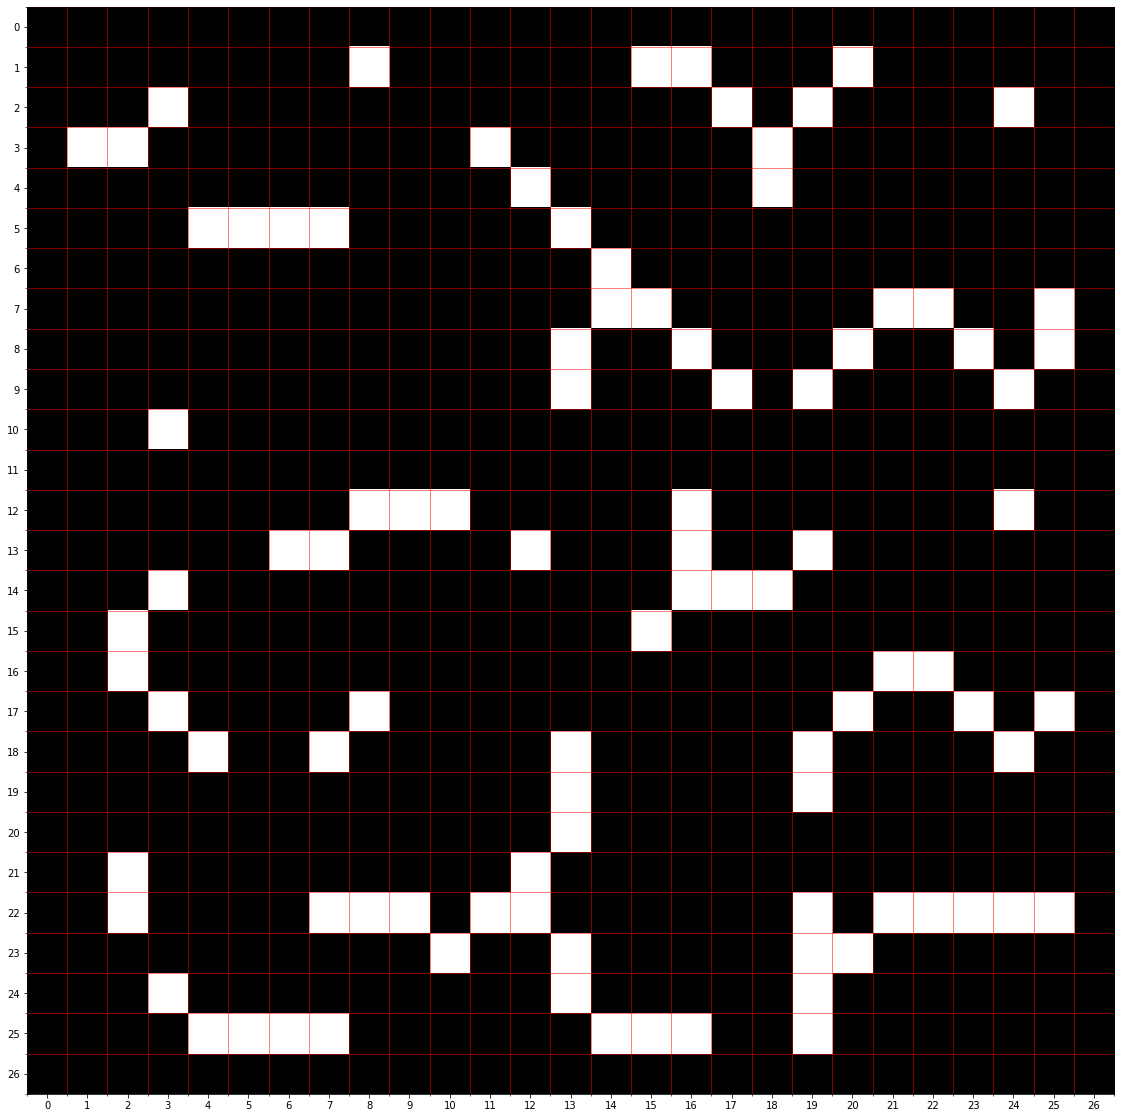

In [28]:
img = padded_test2[:, :, 1]

plt.figure(figsize=(20, 20))  # make the figure larger
plt.imshow(img, cmap="gray")

h, w = img.shape

# Major ticks (with labels)
plt.xticks(np.arange(0, w, 1))
plt.yticks(np.arange(0, h, 1))

# Minor ticks (for grid at pixel edges)
plt.gca().set_xticks(np.arange(-0.5, w, 1), minor=True)
plt.gca().set_yticks(np.arange(-0.5, h, 1), minor=True)

# Grid lines
plt.grid(True, which='minor', color='red', linewidth=0.5)

plt.show()


In [14]:
sk2 = np.expand_dims(test2, axis = - 1)
sk2 = np.pad(sk2, pad_width = 1, mode = 'constant')


plt.imshow(skel2[:, :, 1], cmap = 'gray')

NameError: name 'skel2' is not defined

NameError: name 'lm' is not defined

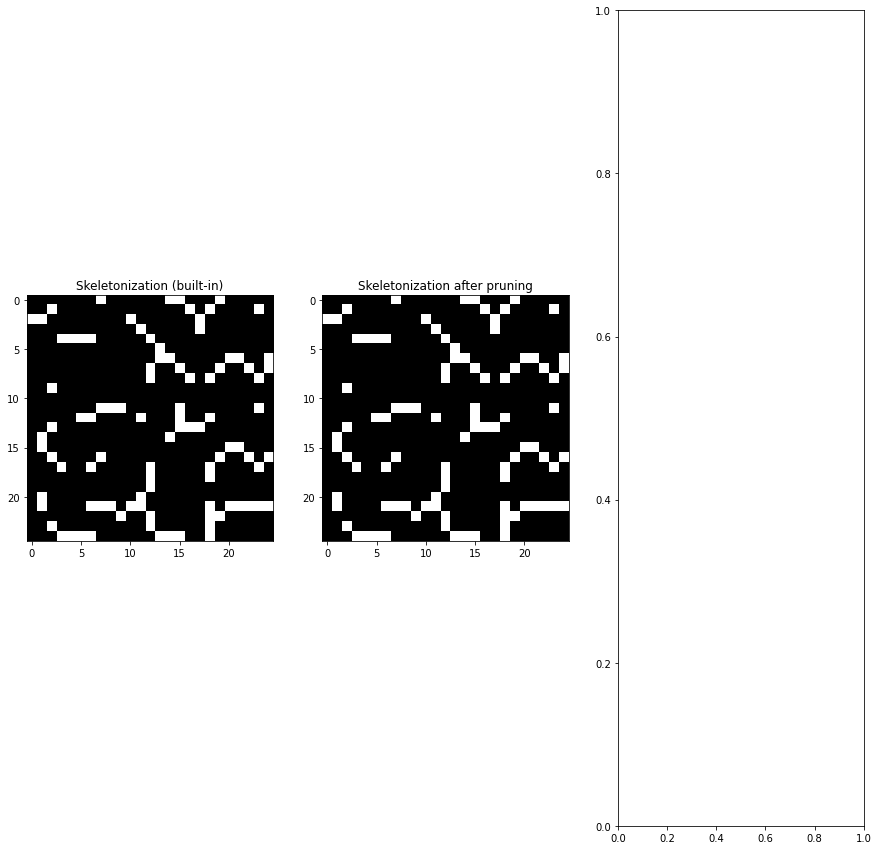

In [ ]:
fig, ax = plt.subplots(1, 3, figsize = (15, 15))

ax[0].imshow(test, cmap = 'gray')
ax[0].set_title("Skeletonization (built-in)")

ax[1].imshow(test2, cmap = 'gray')
ax[1].set_title("Skeletonization after pruning")

ax[2].imshow(np.reshape(lm, test2.shape), cmap = 'gray')
ax[2].set_title("Skeletonization (built-in + algo)")